# Can a model predict match results better than an Elo rating?

Before every match of a season, five methods give a probability to each result —
home win, draw, away win:

| Method | What it knows |
|---|---|
| **League base rates** | how often each result happens in that league; nothing about either club |
| **Elo rating** | one running strength number per club, nudged after every result |
| **Form model** (#1) | each side's last five matches — points, goals, non-penalty xG, xPTS — season to date, and last season |
| **Dixon-Coles on goals** (#2) | each club's attack and defence, fitted to scorelines; predicts the goals, then the result |
| **Dixon-Coles on xG** (#2) | the same, fitted to each side's xG instead of its goals |

**Why it matters.** Part 2 found that xG difference carries information that points
do not. If that is true, a model built on xG should forecast results better than one
built on results alone. Elo is the bar: a strong, simple baseline that has absorbed
every result since August 2024.

**How the answer was earned.** Nothing is fitted in this notebook. It reads
`reports/match_outcome.json`, written by `python -m football_ml.train match_outcome`:
every setting was chosen on 2024/25 (validation), then 2025/26 was walked forward
month by month and scored **once**.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from football_ml import viz

viz.apply_style()
REPORTS = Path("..") / "reports"

report = json.loads((REPORTS / "match_outcome.json").read_text())
holdout = report["holdout"]
print(report["citation"])

features built from the Gold snapshot exported 2026-09-20T13:41:36+00:00, matches 2024-08-15 to 2026-09-19 (3,733 matches, 94,034 shots)


## 1. The split: nothing is ever predicted from its own future

Every fold trains on all matches strictly before a month and predicts that month. The
first three months are burn-in — every club starts with no history. Model and setting
choices were made on the blue months only; the orange months were scored once, with
everything already fixed. The season in progress is used for nothing.

The features themselves are tested too: every feature row records the latest date it
read, and a dbt test fails if that is on or after the match. The test suite plants
leaks on purpose — a rolling window that includes the match, a season summary joined
on the current season — and checks that this test, by name, is what catches them.

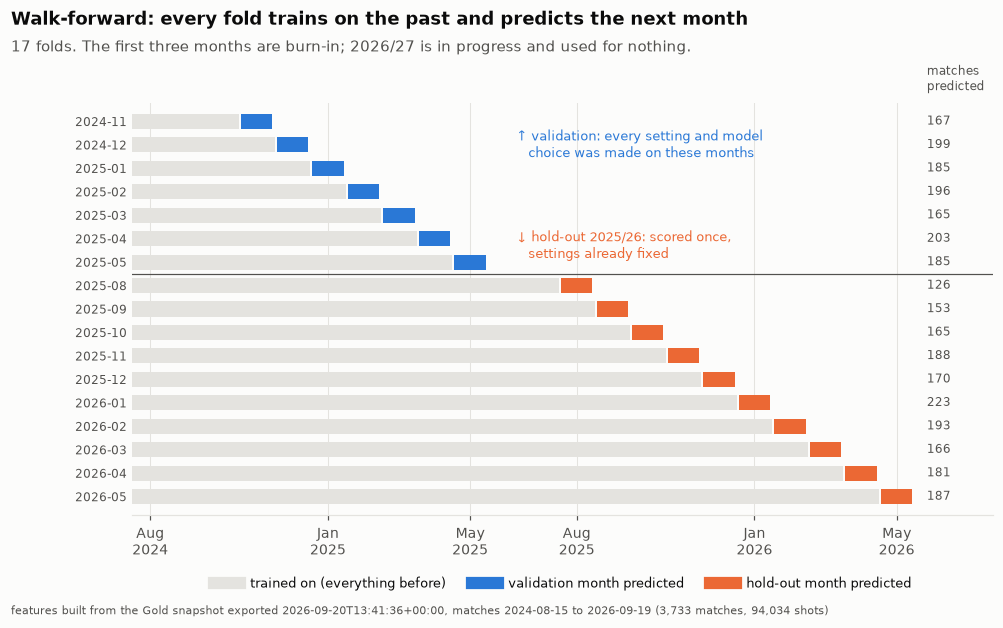

In [2]:
fig = viz.split_timeline(report["plan"])
viz.annotate_source(fig, report["citation"])
plt.show()

## 2. The scores

The headline metric is the **ranked probability score** (RPS): how far the three
probabilities were from what happened, treating the results as ordered — 50% on a draw
is closer to a home win than 50% on an away win. 0 is perfect; lower is better. Log
loss and Brier sit beside it. Accuracy is not shown: it ignores the probabilities,
which are the product.

In [3]:
names = viz.METHOD_NAMES
scores = (
    pd.DataFrame(holdout["scores"]).T[["rps", "log_loss", "brier"]]
    .rename(index=names, columns={"rps": "RPS", "log_loss": "log loss", "brier": "Brier"})
    .sort_values("RPS")
)
print(f"Hold-out {holdout['season']}, {holdout['n']:,} matches\n")
print(scores.round(4).to_string())

Hold-out 2025/26, 1,752 matches

                       RPS  log loss   Brier
Dixon-Coles, xG     0.2045    1.0026  0.5979
Dixon-Coles, goals  0.2054    1.0040  0.5995
Elo rating          0.2076    1.0103  0.6046
Form model (#1)     0.2091    1.0225  0.6105
League base rates   0.2293    1.0731  0.6489


## 3. Better, or inside the noise?

Every difference is a **paired bootstrap over matches**: both methods scored the same
matches, so matches are resampled and the difference re-measured 10,000 times (seeded).
A method is called better only when the whole 95% interval is on one side of zero.

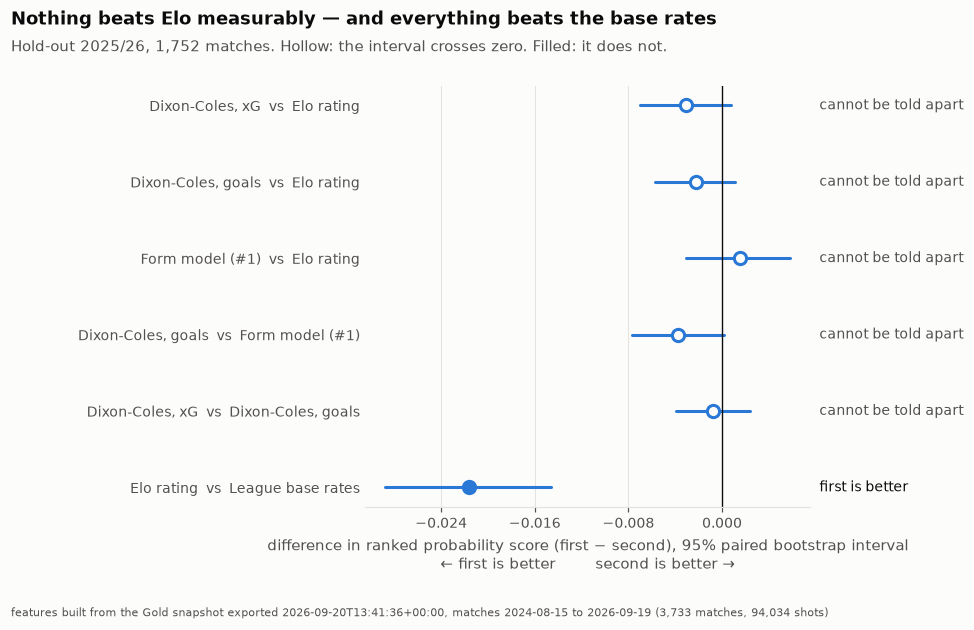

In [4]:
pairs = [
    ("dc_xg", "elo"), ("dc_goals", "elo"), ("model", "elo"),
    ("dc_goals", "model"), ("dc_xg", "dc_goals"), ("elo", "base_rates"),
]
fig = viz.interval_plot(
    holdout["comparisons"], pairs, metric="rps", unit="ranked probability score"
)
viz.title_block(
    fig,
    "Nothing beats Elo measurably — and everything beats the base rates",
    "Hold-out 2025/26, 1,752 matches. Hollow: the interval crosses zero. Filled: it does not.",
)
viz.annotate_source(fig, report["citation"])
plt.show()

## 4. Calibration: does 60% mean 60%?

A probability is only useful if it comes true as often as it says. Each panel bins the
forecasts for one outcome and plots what was said against what happened; the diagonal
is perfect calibration. Shown for Dixon-Coles on xG and for Elo.

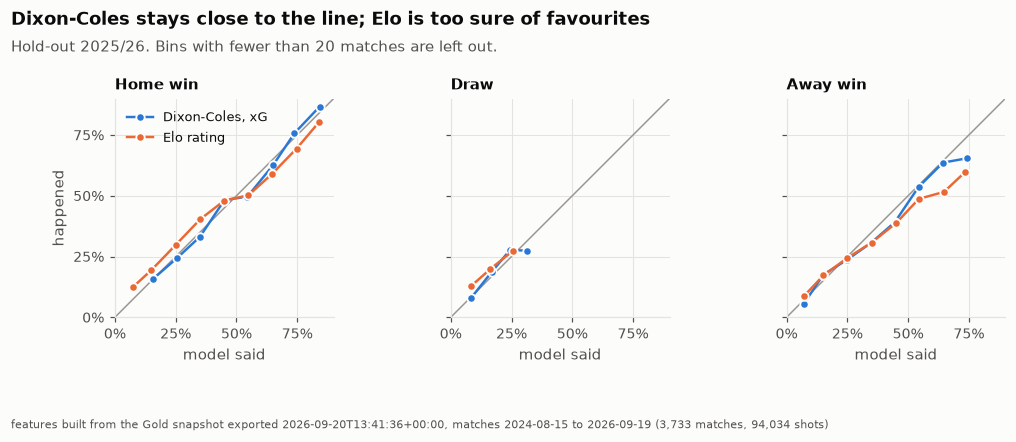

In [5]:
fig = viz.reliability(holdout["calibration"], ["dc_xg", "elo"])
viz.title_block(
    fig,
    "Dixon-Coles stays close to the line; Elo is too sure of favourites",
    "Hold-out 2025/26. Bins with fewer than 20 matches are left out.",
)
viz.annotate_source(fig, report["citation"])
plt.show()

## 5. Draws

A model can post a respectable score while never once making a draw the most likely
result. Draws are a quarter of all matches, so this is checked directly.

In [6]:
draws = (
    pd.DataFrame(holdout["draws"]).T.rename(index=names)
    .rename(columns={
        "actual_draw_rate": "actual draw rate",
        "mean_predicted_draw": "mean P(draw)",
        "draw_most_likely_share": "draw most likely in",
    })
)
print(draws.round(3).to_string())

                    actual draw rate  mean P(draw)  draw most likely in
League base rates              0.255         0.249                0.000
Elo rating                     0.255         0.232                0.000
Form model (#1)                0.255         0.241                0.066
Dixon-Coles, goals             0.255         0.249                0.003
Dixon-Coles, xG                0.255         0.228                0.000


## 6. Clubs with little history

Every club had no history in August 2024, and every promoted club arrives with none.
The hold-out is split by whether either side had fewer than five earlier matches.

In [7]:
by_history = pd.DataFrame({
    label: {names[m]: s["rps"] for m, s in block.items()}
    for label, block in holdout["by_history"].items()
})
counts = {label: next(iter(block.values()))["n"] for label, block in holdout["by_history"].items()}
print(f"matches: {counts}\n")
print(by_history.round(4).to_string())

matches: {'short_history': 65, 'full_history': 1687}

                    short_history  full_history
League base rates          0.2221        0.2295
Elo rating                 0.2143        0.2073
Form model (#1)            0.1969        0.2096
Dixon-Coles, goals         0.2004        0.2055
Dixon-Coles, xG            0.2154        0.2041


## 7. The hold-out was looked at once

Each method's hold-out score is recorded in a ledger keyed by a fingerprint of its
settings, features and folds. A re-run with nothing changed reproduces the same entry;
changing anything and re-scoring would add a second, visible here.

In [8]:
ledger = {
    names[m]: f"{len(entries)} evaluation(s), first on {entries[0]['date']}"
    for m, entries in report["holdout_evaluations"].items()
}
print("\n".join(f"{m:24} {v}" for m, v in ledger.items()))

League base rates        1 evaluation(s), first on 2026-09-29
Elo rating               1 evaluation(s), first on 2026-09-29
Form model (#1)          1 evaluation(s), first on 2026-09-29
Dixon-Coles, goals       1 evaluation(s), first on 2026-09-30
Dixon-Coles, xG          1 evaluation(s), first on 2026-09-30


## Answer

**No model here forecasts results measurably better than an Elo rating.** On the
2025/26 hold-out, Dixon-Coles fitted to xG has the best score of the five (RPS 0.2045
against Elo's 0.2076), but its 95% interval against Elo runs from −0.0070 to +0.0008
and crosses zero. The same holds for Dixon-Coles on goals and for the form model. All
of them beat league base rates clearly.

**Where they differ is calibration.** Elo and the form model are too sure of
favourites — an away win given 65% happened about 52% of the time — while the
Dixon-Coles models stay close to the diagonal. A calibrated probability is the more
useful one even when the ranking score cannot separate them.

**Modelling goals beat modelling the result on log loss** (Dixon-Coles on goals
against the form model: −0.0185, interval −0.0331 to −0.0039), not measurably on RPS.
Fitting to xG instead of goals could not be told apart on the hold-out, although it led
clearly on validation.

**Caveats.**
- One hold-out season, 1,752 matches. Differences of 0.002–0.003 RPS are the size
  that one season cannot resolve; a "cannot be told apart" here is not proof of equality.
- History starts in August 2024, so every rating and form feature is younger than a
  club's real record. The short-history split rests on 65 matches and has no interval.
- Draws: no model makes a draw the most likely result in more than a few percent of
  matches, while a quarter of matches are draws. Calibrated on draws is not the same
  as able to call them.
- Compared with base rates and Elo only. Gold holds no betting odds, so there is no
  market benchmark here, and nothing claims to beat one.
- No causal reading: what a model uses is not what wins matches.